# Rotation registration on random Gaussian images

Estimate an unknown in-plane rotation of a random grayscale image after additive Gaussian noise. The image is not a natural photograph: every pixel is drawn independently from a standard normal. That removes scene structure and leaves interpolation, noise, and the valid-region mask as the main sources of error.

The registration method is classical SSD over a rotation-only warp. OpenCV and scikit-image are not required. SciPy's `ndimage.rotate` (bilinear) supplies the warp, a coarse angular grid finds a basin, and `scipy.optimize.minimize_scalar` refines the angle. The notebook runs on CPU only.

Results and figures are written under `results/rotation_registration/`. That directory is local experiment output; it is separate from the diffusion notebooks.


## 1. Configuration

`N_TRIALS` defaults to 100 per noise level. Reduce it for a quick check. The angular search stays inside `ANGLE_BOUNDS`, the same interval used to draw the ground-truth angle.


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.optimize import minimize_scalar

SEED = 42
IMAGE_SIZE = 64
ANGLE_BOUNDS = (-30.0, 30.0)  # degrees
NOISE_LEVELS = [0.0, 0.1, 0.25, 0.5, 1.0]
N_TRIALS = 100
COARSE_STEP_DEG = 1.0
ROTATE_ORDER = 1  # bilinear
OUTPUT_DIR = Path("results/rotation_registration")
FIGURES_DIR = OUTPUT_DIR / "figures"

# Optional timing sweep. Keep trial counts small; this is only a scaling check.
TIMING_SIZES = [32, 64, 128, 256]
TIMING_TRIALS = 20
TIMING_NOISE = 0.25

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"image {IMAGE_SIZE}x{IMAGE_SIZE}, trials/noise={N_TRIALS}, noise levels={NOISE_LEVELS}")
print(f"output -> {OUTPUT_DIR.resolve()}")


image 64x64, trials/noise=100, noise levels=[0.0, 0.1, 0.25, 0.5, 1.0]
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\rotation_registration


## 2. Method

**Generation.** Draw $I \in \mathbb{R}^{N \times N}$ with $I_{ij} \sim \mathcal{N}(0,1)$. Sample $\theta_\mathrm{true}$ uniformly from $[\theta_\min, \theta_\max]$. Form the observation
$$
Y = R_{\theta_\mathrm{true}}(I) + \sigma \, \varepsilon, \qquad \varepsilon_{ij} \sim \mathcal{N}(0,1),
$$
where $R_\theta$ is a center rotation with bilinear interpolation and constant fill 0 outside the domain.

**Valid region.** Rotating a square leaves a filled border. Comparing candidates on different numbers of pixels would favor some angles. The fixed mask $M$ is the intersection of validity masks for a dense set of angles covering $[\theta_\min, \theta_\max]$. A pixel is valid under angle $\theta$ if rotating a constant-one image by $\theta$ leaves that pixel above $1 - 10^{-3}$. All SSD scores use the same $M$.

**Objective.** For a candidate $\theta$,
$$
J(\theta) = \sum_{(i,j) \in M} \bigl(R_\theta(I)_{ij} - Y_{ij}\bigr)^2.
$$

**Optimization.** Evaluate $J$ on a coarse grid with step `COARSE_STEP_DEG`, then run Brent's method (`minimize_scalar`) in a one-step neighborhood of the coarse minimum, clipped to the angle bounds. The search is rotation-only: there is no translation parameter.

**Limitations.** Bilinear interpolation low-passes the random field, so even $\sigma = 0$ leaves a small residual. The objective can have local minima when noise is large; the coarse grid reduces that risk but does not remove it. Fill value 0 is not distribution-matched to $\mathcal{N}(0,1)$ pixels, which is why the valid mask excludes the border. The center of rotation is known and fixed.


In [2]:
def rotate_image(image: np.ndarray, angle_deg: float) -> np.ndarray:
    return ndimage.rotate(
        image,
        angle=float(angle_deg),
        reshape=False,
        order=ROTATE_ORDER,
        mode="constant",
        cval=0.0,
        prefilter=True,
    )


def validity_mask_for_angle(shape: tuple[int, int], angle_deg: float) -> np.ndarray:
    ones = np.ones(shape, dtype=np.float64)
    rotated = rotate_image(ones, angle_deg)
    return rotated > (1.0 - 1e-3)


def fixed_valid_mask(shape: tuple[int, int], angle_min: float, angle_max: float, step: float = 1.0) -> np.ndarray:
    angles = np.arange(angle_min, angle_max + 0.5 * step, step)
    mask = np.ones(shape, dtype=bool)
    for angle in angles:
        mask &= validity_mask_for_angle(shape, float(angle))
    if not mask.any():
        raise RuntimeError("valid mask is empty; widen the image or shrink the angle range")
    return mask


def ssd(a: np.ndarray, b: np.ndarray, mask: np.ndarray) -> float:
    residual = (a[mask] - b[mask]).astype(np.float64)
    return float(np.dot(residual, residual))


def angular_error_deg(estimated: float, truth: float) -> float:
    # Search stays in a 60-degree window, so wrapping is unnecessary, but keep the
    # principal difference for safety if a refined angle sits just outside the box.
    return float(abs(((estimated - truth + 180.0) % 360.0) - 180.0))


VALID_MASK = fixed_valid_mask((IMAGE_SIZE, IMAGE_SIZE), ANGLE_BOUNDS[0], ANGLE_BOUNDS[1], step=1.0)
print(f"valid pixels: {int(VALID_MASK.sum())} / {IMAGE_SIZE * IMAGE_SIZE} ({100 * VALID_MASK.mean():.1f}%)")


valid pixels: 3124 / 4096 (76.3%)


In [3]:
def coarse_search(template: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> tuple[float, np.ndarray, np.ndarray]:
    lo, hi = ANGLE_BOUNDS
    candidates = np.arange(lo, hi + 0.5 * COARSE_STEP_DEG, COARSE_STEP_DEG)
    values = np.empty(candidates.shape, dtype=np.float64)
    for i, angle in enumerate(candidates):
        values[i] = ssd(rotate_image(template, angle), observation, mask)
    return float(candidates[int(np.argmin(values))]), candidates, values


def refine_angle(template: np.ndarray, observation: np.ndarray, mask: np.ndarray, coarse_angle: float) -> float:
    lo, hi = ANGLE_BOUNDS
    bracket_lo = max(lo, coarse_angle - COARSE_STEP_DEG)
    bracket_hi = min(hi, coarse_angle + COARSE_STEP_DEG)
    if bracket_hi <= bracket_lo:
        return float(np.clip(coarse_angle, lo, hi))

    def objective(angle: float) -> float:
        return ssd(rotate_image(template, angle), observation, mask)

    result = minimize_scalar(objective, bounds=(bracket_lo, bracket_hi), method="bounded", options={"xatol": 1e-4})
    if not result.success:
        return float(coarse_angle)
    return float(result.x)


def register_rotation(template: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> dict:
    started = time.perf_counter()
    coarse_angle, candidates, values = coarse_search(template, observation, mask)
    estimated = refine_angle(template, observation, mask, coarse_angle)
    elapsed = time.perf_counter() - started
    return {
        "estimated_angle": estimated,
        "coarse_angle": coarse_angle,
        "candidates": candidates,
        "ssd_curve": values,
        "runtime_s": elapsed,
        "ssd_at_estimate": ssd(rotate_image(template, estimated), observation, mask),
    }


def make_trial(rng: np.random.Generator, size: int, noise_std: float, mask: np.ndarray) -> dict:
    template = rng.standard_normal((size, size)).astype(np.float64)
    true_angle = float(rng.uniform(ANGLE_BOUNDS[0], ANGLE_BOUNDS[1]))
    observation = rotate_image(template, true_angle) + noise_std * rng.standard_normal((size, size))
    fit = register_rotation(template, observation, mask)
    err = angular_error_deg(fit["estimated_angle"], true_angle)
    return {
        "template": template,
        "observation": observation,
        "true_angle": true_angle,
        "noise_std": noise_std,
        "angular_error": err,
        **fit,
    }


# Warm-up + single-trial timing for the default size.
_warmup_rng = np.random.default_rng(0)
_t0 = time.perf_counter()
_ = make_trial(_warmup_rng, IMAGE_SIZE, 0.25, VALID_MASK)
print(f"one {IMAGE_SIZE}x{IMAGE_SIZE} trial took {time.perf_counter() - _t0:.3f}s")
print(f"rough full-run estimate: {N_TRIALS * len(NOISE_LEVELS) * (time.perf_counter() - _t0):.1f}s "
      f"({N_TRIALS} trials x {len(NOISE_LEVELS)} noise levels)")


one 64x64 trial took 0.008s
rough full-run estimate: 4.3s (100 trials x 5 noise levels)


## 3. Example trial

One draw at a moderate noise level, with the original field, the clean rotation, and the noisy observation. The recovered angle is annotated on the second figure. The SSD curve uses the same fixed valid mask as the optimizer.


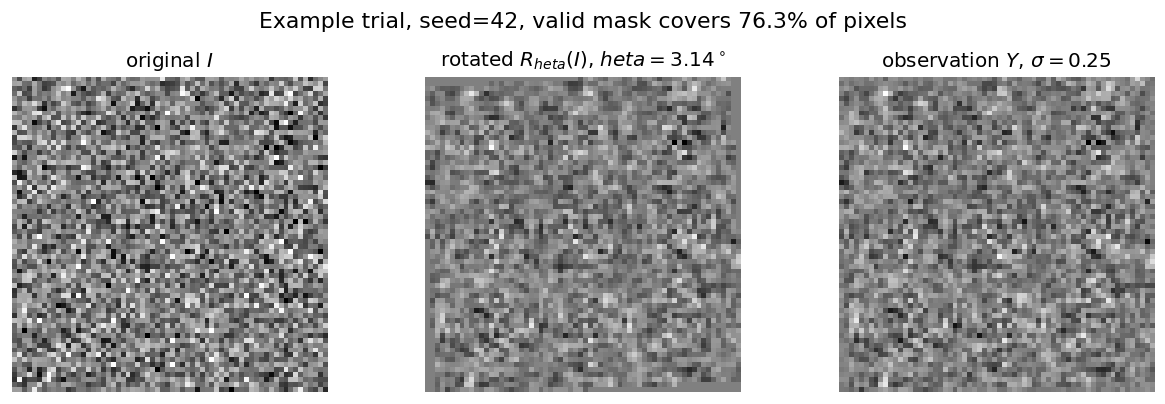

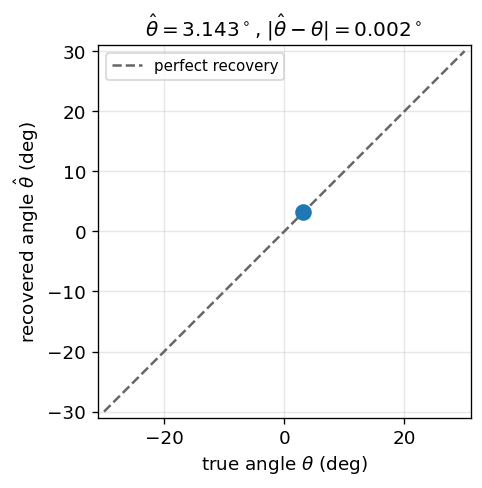

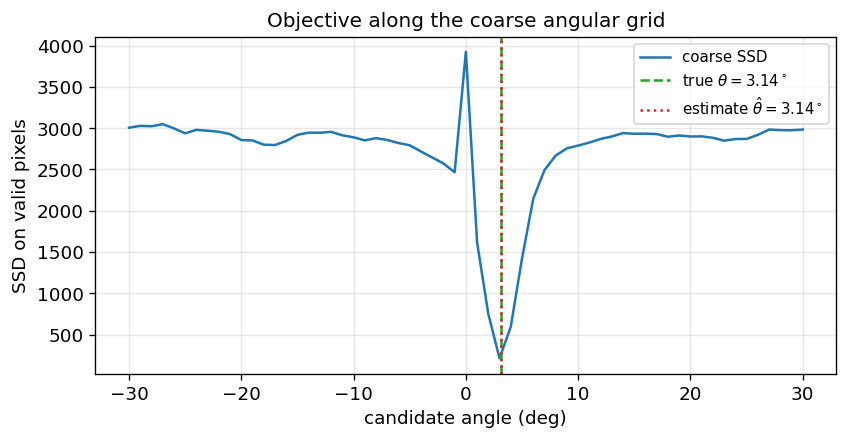

true=3.1415 deg, coarse=3.0000, refined=3.1432, error=0.0016 deg, runtime=0.008s


In [4]:
example_rng = np.random.default_rng(SEED)
example = make_trial(example_rng, IMAGE_SIZE, noise_std=0.25, mask=VALID_MASK)
clean_rotated = rotate_image(example["template"], example["true_angle"])

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
panels = [
    (example["template"], "original $I$"),
    (clean_rotated, fr"rotated $R_{{	heta}}(I)$, $	heta={example['true_angle']:.2f}^\circ$"),
    (example["observation"], fr"observation $Y$, $\sigma={example['noise_std']}$"),
]
vmax = np.percentile(np.abs(example["template"]), 99)
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"Example trial, seed={SEED}, valid mask covers {100 * VALID_MASK.mean():.1f}% of pixels")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_images.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.scatter([example["true_angle"]], [example["estimated_angle"]], s=80, zorder=3)
ax.plot(ANGLE_BOUNDS, ANGLE_BOUNDS, color="0.4", ls="--", label="perfect recovery")
ax.set_xlim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
ax.set_ylim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
ax.set_xlabel(r"true angle $\theta$ (deg)")
ax.set_ylabel(r"recovered angle $\hat{\theta}$ (deg)")
ax.set_title(
    fr"$\hat{{\theta}}={example['estimated_angle']:.3f}^\circ$, "
    fr"$|\hat{{\theta}}-\theta|={example['angular_error']:.3f}^\circ$"
)
ax.set_aspect("equal")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_true_vs_recovered.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(example["candidates"], example["ssd_curve"], color="C0", label="coarse SSD")
ax.axvline(example["true_angle"], color="C2", ls="--", label=fr"true $\theta={example['true_angle']:.2f}^\circ$")
ax.axvline(example["estimated_angle"], color="C3", ls=":", label=fr"estimate $\hat{{\theta}}={example['estimated_angle']:.2f}^\circ$")
ax.set_xlabel("candidate angle (deg)")
ax.set_ylabel("SSD on valid pixels")
ax.set_title("Objective along the coarse angular grid")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_ssd_curve.png", bbox_inches="tight")
plt.show()

print(
    f"true={example['true_angle']:.4f} deg, "
    f"coarse={example['coarse_angle']:.4f}, "
    f"refined={example['estimated_angle']:.4f}, "
    f"error={example['angular_error']:.4f} deg, "
    f"runtime={example['runtime_s']:.3f}s"
)


## 4. Full experiment

Identical ground-truth images and angles are reused across noise levels. For trial $k$, the template and $\theta_\mathrm{true}$ are drawn from a dedicated RNG stream; only the noise realization changes with $\sigma$. That keeps the comparison across noise levels matched.


In [5]:
def run_experiment(
    n_trials: int,
    noise_levels: list[float],
    size: int,
    seed: int,
) -> pd.DataFrame:
    mask = fixed_valid_mask((size, size), ANGLE_BOUNDS[0], ANGLE_BOUNDS[1], step=1.0)
    rows = []
    experiment_started = time.perf_counter()
    total = n_trials * len(noise_levels)
    done = 0
    for trial in range(n_trials):
        trial_rng = np.random.default_rng(seed + 10_000 * trial + size)
        template = trial_rng.standard_normal((size, size)).astype(np.float64)
        true_angle = float(trial_rng.uniform(ANGLE_BOUNDS[0], ANGLE_BOUNDS[1]))
        clean = rotate_image(template, true_angle)
        for noise_std in noise_levels:
            noise_rng = np.random.default_rng(seed + 10_000 * trial + int(1_000_000 * noise_std) + 7)
            observation = clean + noise_std * noise_rng.standard_normal((size, size))
            fit = register_rotation(template, observation, mask)
            rows.append({
                "trial": trial,
                "image_size": size,
                "noise_std": float(noise_std),
                "true_angle": true_angle,
                "estimated_angle": fit["estimated_angle"],
                "coarse_angle": fit["coarse_angle"],
                "angular_error": angular_error_deg(fit["estimated_angle"], true_angle),
                "ssd_at_estimate": fit["ssd_at_estimate"],
                "runtime_s": fit["runtime_s"],
                "valid_pixels": int(mask.sum()),
            })
            done += 1
            if done == 1 or done == total or done % max(1, total // 10) == 0:
                elapsed = time.perf_counter() - experiment_started
                rate = done / elapsed
                eta = (total - done) / rate if rate > 0 else float("nan")
                print(
                    f"[{done}/{total}] trial {trial}, sigma={noise_std:g}, "
                    f"err={rows[-1]['angular_error']:.4f} deg, "
                    f"elapsed {elapsed:.1f}s, about {eta:.1f}s left",
                    flush=True,
                )
    return pd.DataFrame(rows)


results = run_experiment(N_TRIALS, NOISE_LEVELS, IMAGE_SIZE, SEED)
results_path = OUTPUT_DIR / "trial_results.csv"
results.to_csv(results_path, index=False)
print(f"wrote {results_path} ({len(results)} rows)")


[1/500] trial 0, sigma=0, err=0.0000 deg, elapsed 0.0s, about 4.6s left


[50/500] trial 9, sigma=1, err=0.0352 deg, elapsed 0.4s, about 3.8s left


[100/500] trial 19, sigma=1, err=0.0512 deg, elapsed 0.9s, about 3.5s left


[150/500] trial 29, sigma=1, err=0.0288 deg, elapsed 1.3s, about 3.0s left


[200/500] trial 39, sigma=1, err=0.0126 deg, elapsed 1.7s, about 2.6s left


...

[350/500] trial 69, sigma=1, err=0.0631 deg, elapsed 3.1s, about 1.3s left


[400/500] trial 79, sigma=1, err=0.0185 deg, elapsed 3.5s, about 0.9s left


[450/500] trial 89, sigma=1, err=0.0676 deg, elapsed 3.9s, about 0.4s left


[500/500] trial 99, sigma=1, err=0.0143 deg, elapsed 4.3s, about 0.0s left


wrote results\rotation_registration\trial_results.csv (500 rows)


## 5. Summary table and interpretation plots


In [6]:
summary = (
    results.groupby("noise_std")
    .agg(
        n=("angular_error", "count"),
        mean_abs_error_deg=("angular_error", "mean"),
        median_abs_error_deg=("angular_error", "median"),
        std_abs_error_deg=("angular_error", "std"),
        mean_runtime_s=("runtime_s", "mean"),
        median_runtime_s=("runtime_s", "median"),
    )
    .reset_index()
)
summary_path = OUTPUT_DIR / "summary_by_noise.csv"
summary.to_csv(summary_path, index=False)
display_cols = {
    "noise_std": "sigma",
    "n": "n",
    "mean_abs_error_deg": "mean |err| (deg)",
    "median_abs_error_deg": "median |err| (deg)",
    "std_abs_error_deg": "std |err| (deg)",
    "mean_runtime_s": "mean runtime (s)",
}
print(summary.rename(columns=display_cols).round(4).to_string(index=False))

zero = summary.loc[np.isclose(summary.noise_std, 0.0)].iloc[0]
print(
    f"\nZero-noise sanity: mean |err|={zero.mean_abs_error_deg:.4f} deg, "
    f"median={zero.median_abs_error_deg:.4f} deg over {int(zero.n)} trials."
)


 sigma   n  mean |err| (deg)  median |err| (deg)  std |err| (deg)  mean runtime (s)  median_runtime_s
  0.00 100            0.0000              0.0000           0.0000            0.0082            0.0082
  0.10 100            0.0032              0.0029           0.0022            0.0083            0.0082
  0.25 100            0.0079              0.0065           0.0064            0.0083            0.0083
  0.50 100            0.0154              0.0124           0.0127            0.0084            0.0085
  1.00 100            0.0340              0.0286           0.0264            0.0087            0.0086

Zero-noise sanity: mean |err|=0.0000 deg, median=0.0000 deg over 100 trials.


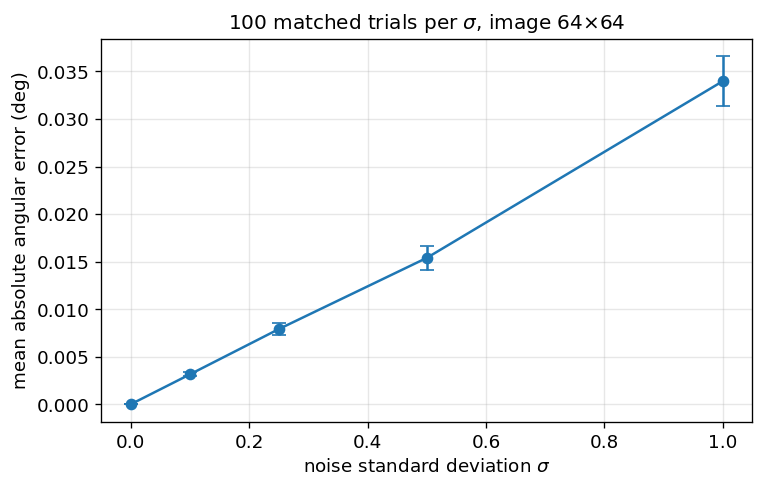

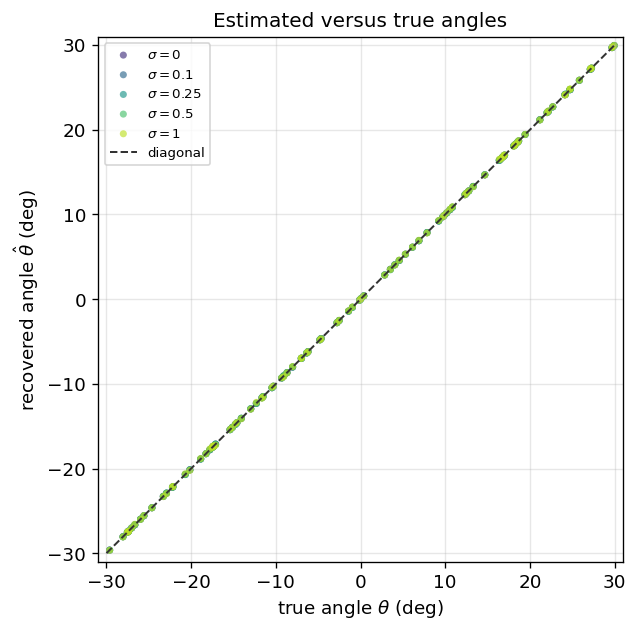

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
means = summary["mean_abs_error_deg"].to_numpy()
stds = summary["std_abs_error_deg"].to_numpy()
ns = summary["n"].to_numpy()
sems = stds / np.sqrt(ns)
ax.errorbar(summary["noise_std"], means, yerr=sems, fmt="-o", capsize=4, color="C0")
ax.set_xlabel(r"noise standard deviation $\sigma$")
ax.set_ylabel("mean absolute angular error (deg)")
ax.set_title(fr"{N_TRIALS} matched trials per $\sigma$, image {IMAGE_SIZE}$\times${IMAGE_SIZE}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_vs_noise.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.8, 5.4))
for noise_std, color in zip(NOISE_LEVELS, plt.cm.viridis(np.linspace(0.15, 0.9, len(NOISE_LEVELS)))):
    block = results.loc[np.isclose(results.noise_std, noise_std)]
    ax.scatter(
        block.true_angle,
        block.estimated_angle,
        s=18,
        alpha=0.65,
        color=color,
        label=fr"$\sigma={noise_std:g}$",
        edgecolors="none",
    )
ax.plot(ANGLE_BOUNDS, ANGLE_BOUNDS, color="0.2", ls="--", lw=1.2, label="diagonal")
ax.set_xlim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
ax.set_ylim(ANGLE_BOUNDS[0] - 1, ANGLE_BOUNDS[1] + 1)
ax.set_aspect("equal")
ax.set_xlabel(r"true angle $\theta$ (deg)")
ax.set_ylabel(r"recovered angle $\hat{\theta}$ (deg)")
ax.set_title("Estimated versus true angles")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "estimated_vs_true.png", bbox_inches="tight")
plt.show()


## 6. Runtime versus image size

A smaller matched experiment at one noise level. Mask construction and registration both scale with the number of pixels and with the cost of each bilinear rotate.


timing size 32...


[1/20] trial 0, sigma=0.25, err=0.0010 deg, elapsed 0.0s, about 0.1s left


[2/20] trial 1, sigma=0.25, err=0.0389 deg, elapsed 0.0s, about 0.1s left


[4/20] trial 3, sigma=0.25, err=0.0795 deg, elapsed 0.0s, about 0.1s left


[6/20] trial 5, sigma=0.25, err=0.0247 deg, elapsed 0.0s, about 0.0s left


...

[14/20] trial 13, sigma=0.25, err=0.0006 deg, elapsed 1.8s, about 0.8s left


[16/20] trial 15, sigma=0.25, err=0.0011 deg, elapsed 2.0s, about 0.5s left


[18/20] trial 17, sigma=0.25, err=0.0007 deg, elapsed 2.3s, about 0.3s left


[20/20] trial 19, sigma=0.25, err=0.0002 deg, elapsed 2.5s, about 0.0s left


 image_size  n_trials  noise_std  mean_runtime_s  median_runtime_s  wall_clock_s  mean_abs_error_deg
         32        20       0.25          0.0031            0.0029        0.0745              0.0248
         64        20       0.25          0.0085            0.0085        0.1931              0.0063
        128        20       0.25          0.0405            0.0401        0.8685              0.0022
        256        20       0.25          0.1205            0.1199        2.6017              0.0005


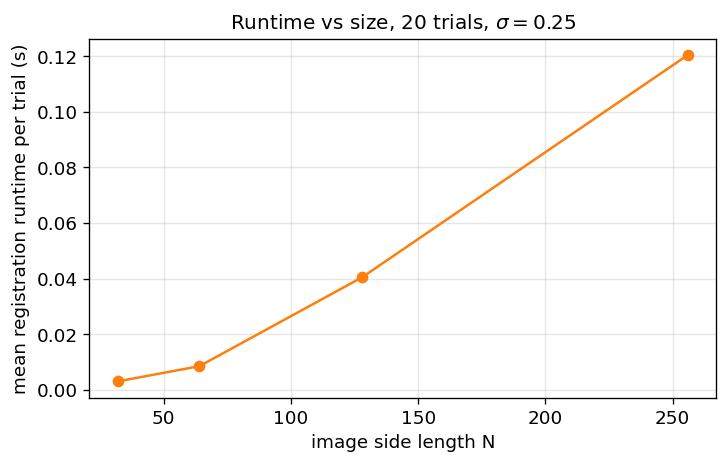

In [8]:
timing_rows = []
for size in TIMING_SIZES:
    print(f"timing size {size}...", flush=True)
    started = time.perf_counter()
    frame = run_experiment(TIMING_TRIALS, [TIMING_NOISE], size, seed=SEED + size)
    wall = time.perf_counter() - started
    timing_rows.append({
        "image_size": size,
        "n_trials": TIMING_TRIALS,
        "noise_std": TIMING_NOISE,
        "mean_runtime_s": float(frame.runtime_s.mean()),
        "median_runtime_s": float(frame.runtime_s.median()),
        "wall_clock_s": wall,
        "mean_abs_error_deg": float(frame.angular_error.mean()),
    })
timing = pd.DataFrame(timing_rows)
timing_path = OUTPUT_DIR / "runtime_by_size.csv"
timing.to_csv(timing_path, index=False)
print(timing.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.plot(timing.image_size, timing.mean_runtime_s, "-o", color="C1")
ax.set_xlabel("image side length N")
ax.set_ylabel("mean registration runtime per trial (s)")
ax.set_title(fr"Runtime vs size, {TIMING_TRIALS} trials, $\sigma={TIMING_NOISE}$")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "runtime_vs_size.png", bbox_inches="tight")
plt.show()


## 7. Saved outputs and HiPerGator notes

**Dependencies.** `numpy`, `scipy`, `matplotlib`, `pandas`. No GPU, OpenCV, or scikit-image.

**Local run.** From the repository root, open this notebook and run all cells, or:

```bash
python -m jupyter nbconvert --to notebook --execute rotation_registration.ipynb --output rotation_registration_executed.ipynb
```

**Faster smoke test.** Set `N_TRIALS = 10` and skip the timing section, or set `TIMING_SIZES = [32, 64]`.

**HiPerGator.** Use the existing `gaussian-rotation` conda env if present (`numpy`/`scipy`/`matplotlib`/`pandas` are already listed in `environment.yml`). CPU-only is enough. Copy the notebook, run it from the repo root on a compute node or OOD Jupyter session, then copy back `results/rotation_registration/`.

**Outputs.**

```text
results/rotation_registration/trial_results.csv
results/rotation_registration/summary_by_noise.csv
results/rotation_registration/runtime_by_size.csv
results/rotation_registration/metadata.json
results/rotation_registration/figures/*.png
```


In [9]:
metadata = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "angle_bounds_deg": list(ANGLE_BOUNDS),
    "noise_levels": NOISE_LEVELS,
    "n_trials": N_TRIALS,
    "coarse_step_deg": COARSE_STEP_DEG,
    "rotate_order": ROTATE_ORDER,
    "interpolation": "scipy.ndimage.rotate bilinear",
    "optimizer": "coarse grid + scipy.optimize.minimize_scalar bounded Brent",
    "objective": "SSD on fixed valid-pixel mask",
    "valid_pixels": int(VALID_MASK.sum()),
    "valid_fraction": float(VALID_MASK.mean()),
    "timing_sizes": TIMING_SIZES,
    "timing_trials": TIMING_TRIALS,
    "timing_noise": TIMING_NOISE,
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

print("Interpretation")
print(
    f"- At sigma=0 the mean absolute error is {zero.mean_abs_error_deg:.4f} deg. "
    "Residual error is from bilinear interpolation of a white-noise field, not from the optimizer missing the basin."
)
best = summary.loc[summary.mean_abs_error_deg.idxmin()]
worst = summary.loc[summary.mean_abs_error_deg.idxmax()]
print(
    f"- Lowest mean error: sigma={best.noise_std:g} -> {best.mean_abs_error_deg:.4f} deg. "
    f"Highest: sigma={worst.noise_std:g} -> {worst.mean_abs_error_deg:.4f} deg."
)
print(
    f"- Mean runtime at {IMAGE_SIZE}x{IMAGE_SIZE}: {summary.mean_runtime_s.mean():.3f}s per registration. "
    f"Timing sweep sizes {list(timing.image_size)} took wall times {timing.wall_clock_s.round(1).tolist()}s."
)
print(f"- Wrote metadata to {OUTPUT_DIR / 'metadata.json'}")


Interpretation
- At sigma=0 the mean absolute error is 0.0000 deg. Residual error is from bilinear interpolation of a white-noise field, not from the optimizer missing the basin.
- Lowest mean error: sigma=0 -> 0.0000 deg. Highest: sigma=1 -> 0.0340 deg.
- Mean runtime at 64x64: 0.008s per registration. Timing sweep sizes [32, 64, 128, 256] took wall times [0.1, 0.2, 0.9, 2.6]s.
- Wrote metadata to results\rotation_registration\metadata.json
